In [5]:
%pip install numpy pandas matplotlib scikit-learn ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\Ana Kelly\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Formato: (9568, 5)
Valores ausentes:
 AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Tarefa 1 - correlação com PE:
AT   -0.9481
V    -0.8698
AP    0.5184
RH    0.3898
Name: PE, dtype: float64


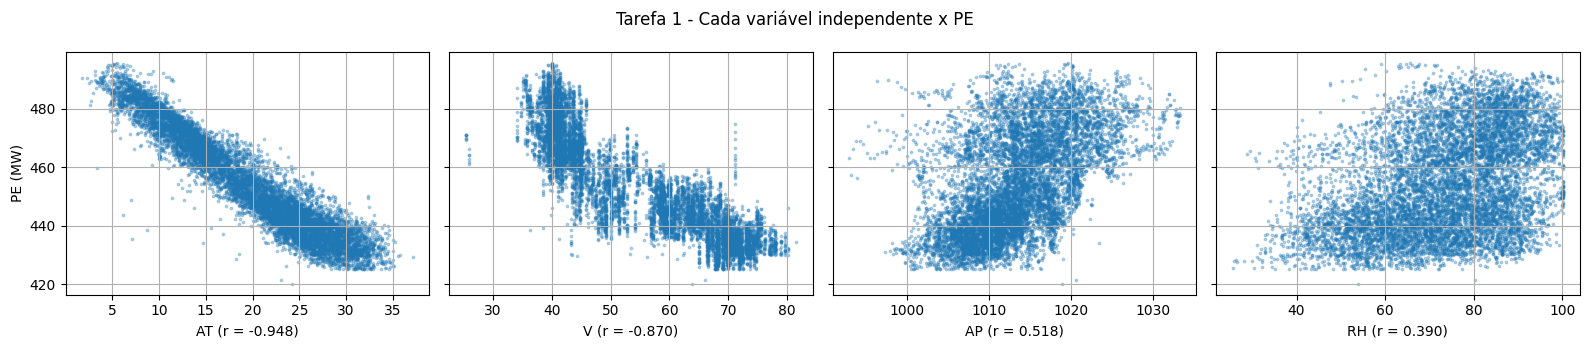


Tarefa 2 - correlação entre as independentes:
      AT     V    AP    RH
AT  1.00  0.84 -0.51 -0.54
V   0.84  1.00 -0.41 -0.31
AP -0.51 -0.41  1.00  0.10
RH -0.54 -0.31  0.10  1.00


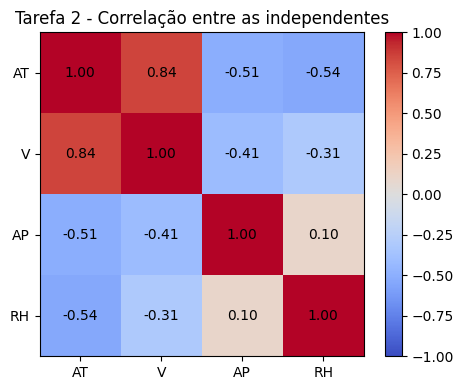


Treino: 7654 | Teste: 1914

Tarefa 3 - intercepto: 454.431
  AT: -14.7639
  V: -2.9496
  AP: 0.3698
  RH: -2.3122

Tarefa 4 - métricas:
  Treino: R2 = 0.9283 | RMSE = 4.5709 MW | MAE = 3.6300 MW
  Teste: R2 = 0.9301 | RMSE = 4.5026 MW | MAE = 3.5959 MW


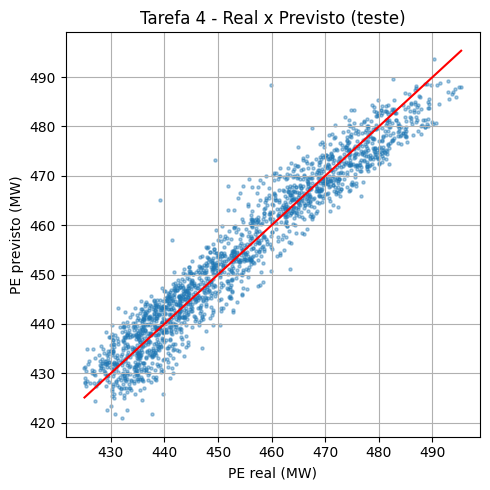

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

FEATURES = ["AT", "V", "AP", "RH"]
TARGET = "PE"
PASTA_IMAGENS = Path("imagens")
PASTA_IMAGENS.mkdir(exist_ok=True)

# Carregar o dataset UCI CCPP direto da internet
ds = fetch_ucirepo(id=294)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
print("Formato:", df.shape)
print("Valores ausentes:\n", df.isna().sum())

# Tarefa 1: correlação das independentes com PE
corr_alvo = df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
print("\nTarefa 1 - correlação com PE:")
print(corr_alvo.round(4))

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for eixo, col in zip(eixos, FEATURES):
    eixo.scatter(df[col], df[TARGET], s=3, alpha=0.3)
    eixo.set_xlabel(f"{col} (r = {corr_alvo[col]:.3f})")
    eixo.grid(True)
eixos[0].set_ylabel("PE (MW)")
fig.suptitle("Tarefa 1 - Cada variável independente x PE")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "tarefa1_dispersao.png", dpi=120)
plt.show()

# Tarefa 2: correlação entre as independentes
corr_x = df[FEATURES].corr()
print("\nTarefa 2 - correlação entre as independentes:")
print(corr_x.round(2))

plt.figure(figsize=(5, 4))
plt.imshow(corr_x, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(4), FEATURES)
plt.yticks(range(4), FEATURES)
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{corr_x.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Tarefa 2 - Correlação entre as independentes")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "tarefa2_correlacao.png", dpi=120)
plt.show()

# Divisão treino (80%) e teste (20%)
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(f"\nTreino: {len(X_train)} | Teste: {len(X_test)}")

# Tratamento de valores ausentes (ajuste só no treino)
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Padronização z-score (ajuste só no treino)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Tarefa 3: regressão linear múltipla
model = LinearRegression()
model.fit(X_train, y_train)
print("\nTarefa 3 - intercepto:", round(model.intercept_, 4))
for nome, coef in zip(FEATURES, model.coef_):
    print(f"  {nome}: {coef:.4f}")

# Tarefa 4: R², RMSE e MAE
print("\nTarefa 4 - métricas:")
for nome, Xs, ys in [("Treino", X_train, y_train), ("Teste", X_test, y_test)]:
    pred = model.predict(Xs)
    print(f"  {nome}: R2 = {r2_score(ys, pred):.4f} | "
          f"RMSE = {np.sqrt(mean_squared_error(ys, pred)):.4f} MW | "
          f"MAE = {mean_absolute_error(ys, pred):.4f} MW")

pred_teste = model.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_teste, s=5, alpha=0.4)
limites = [y_test.min(), y_test.max()]
plt.plot(limites, limites, color="red")
plt.xlabel("PE real (MW)")
plt.ylabel("PE previsto (MW)")
plt.title("Tarefa 4 - Real x Previsto (teste)")
plt.grid(True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "tarefa4_real_previsto.png", dpi=120)
plt.show()